# Bank Loan Approval Prediction

## Major Project – Machine Learning & AI

### Project Objective
To build a machine learning model that predicts whether a loan application is likely to be approved based on applicant information.

### Algorithm
Random Forest Classifier

### Tools and Technologies
- Python
- Jupyter Notebook
- Pandas
- NumPy
- Matplotlib
- Seaborn
- Scikit-learn

In [1]:
import os 
print(os.listdir())

['train.csv', 'Bank_Loan_Approval_Prediction.ipynb', '.ipynb_checkpoints']


In [2]:
import pandas as pd 
print("pandas imported successfully!")

pandas imported successfully!


In [3]:
df = pd.read_csv("train.csv")

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

Dataset loaded successfully!
Dataset shape: (614, 13)


In [4]:
df.head()

,Loan_ID,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status
0,LP001002,Male,No,0,Graduate,No,5849,0.0,NaN,360.0,1.0,Urban,Y
1,LP001003,Male,Yes,1,Graduate,No,4583,1508.0,128.0,360.0,1.0,Rural,N
2,LP001005,Male,Yes,0,Graduate,Yes,3000,0.0,66.0,360.0,1.0,Urban,Y
3,LP001006,Male,Yes,0,Not Graduate,No,2583,2358.0,120.0,360.0,1.0,Urban,Y
4,LP001008,Male,No,0,Graduate,No,6000,0.0,141.0,360.0,1.0,Urban,Y


In [5]:
print("Column names:")
print(df.columns)

print("\nDataset information:")
df.info()

Column names:
Index(['Loan_ID', 'Gender', 'Married', 'Dependents', 'Education',
       'Self_Employed', 'ApplicantIncome', 'CoapplicantIncome', 'LoanAmount',
       'Loan_Amount_Term', 'Credit_History', 'Property_Area', 'Loan_Status'],
      dtype='object')

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 614 entries, 0 to 613
Data columns (total 13 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Loan_ID            614 non-null    object 
 1   Gender             601 non-null    object 
 2   Married            611 non-null    object 
 3   Dependents         599 non-null    object 
 4   Education          614 non-null    object 
 5   Self_Employed      582 non-null    object 
 6   ApplicantIncome    614 non-null    int64  
 7   CoapplicantIncome  614 non-null    float64
 8   LoanAmount         592 non-null    float64
 9   Loan_Amount_Term   600 non-null    float64
 10  Credit_History     564 non-null   

In [6]:
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

Number of rows: 614
Number of columns: 13


In [7]:
print(df.isnull().sum())

Loan_ID               0
Gender               13
Married               3
Dependents           15
Education             0
Self_Employed        32
ApplicantIncome       0
CoapplicantIncome     0
LoanAmount           22
Loan_Amount_Term     14
Credit_History       50
Property_Area         0
Loan_Status           0
dtype: int64


In [8]:
print(df.head())
print("\nLoan approval values:")
print(df["Loan_Status"].value_counts())

    Loan_ID Gender Married Dependents     Education Self_Employed  \
0  LP001002   Male      No          0      Graduate            No   
1  LP001003   Male     Yes          1      Graduate            No   
2  LP001005   Male     Yes          0      Graduate           Yes   
3  LP001006   Male     Yes          0  Not Graduate            No   
4  LP001008   Male      No          0      Graduate            No   

   ApplicantIncome  CoapplicantIncome  LoanAmount  Loan_Amount_Term  \
0             5849                0.0         NaN             360.0   
1             4583             1508.0       128.0             360.0   
2             3000                0.0        66.0             360.0   
3             2583             2358.0       120.0             360.0   
4             6000                0.0       141.0             360.0   

   Credit_History Property_Area Loan_Status  
0             1.0         Urban           Y  
1             1.0         Rural           N  
2             1.0   

In [9]:
print(df.isnull().sum())

Loan_ID               0
Gender               13
Married               3
Dependents           15
Education             0
Self_Employed        32
ApplicantIncome       0
CoapplicantIncome     0
LoanAmount           22
Loan_Amount_Term     14
Credit_History       50
Property_Area         0
Loan_Status           0
dtype: int64


In [10]:
# Fill missing numerical values with the median
for col in df.select_dtypes(include="number").columns:
    df[col] = df[col].fillna(df[col].median())

# Fill missing categorical values with the most frequent value
for col in df.select_dtypes(include="object").columns:
    if df[col].isnull().sum() > 0:
        df[col] = df[col].fillna(df[col].mode()[0])

print("Missing values handled successfully!")

Missing values handled successfully!


In [11]:
print(df.isnull().sum())

Loan_ID              0
Gender               0
Married              0
Dependents           0
Education            0
Self_Employed        0
ApplicantIncome      0
CoapplicantIncome    0
LoanAmount           0
Loan_Amount_Term     0
Credit_History       0
Property_Area        0
Loan_Status          0
dtype: int64


In [12]:
print(df.columns.tolist())

['Loan_ID', 'Gender', 'Married', 'Dependents', 'Education', 'Self_Employed', 'ApplicantIncome', 'CoapplicantIncome', 'LoanAmount', 'Loan_Amount_Term', 'Credit_History', 'Property_Area', 'Loan_Status']


In [13]:
# Features: information used to make predictions
X = df.drop("Loan_Status", axis=1)

# Target: the result we want to predict
y = df["Loan_Status"]

print("Features shape:", X.shape)
print("Target shape:", y.shape)
print("\nTarget values:")
print(y.value_counts())

Features shape: (614, 12)
Target shape: (614,)

Target values:
Loan_Status
Y    422
N    192
Name: count, dtype: int64


In [14]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training rows:", X_train.shape[0])
print("Testing rows:", X_test.shape[0])

Training rows: 491
Testing rows: 123


In [15]:
import pandas as pd

# Convert categorical columns into numerical columns
X_train_encoded = pd.get_dummies(X_train, dtype=int)
X_test_encoded = pd.get_dummies(X_test, dtype=int)

# Make sure both datasets have the same columns
X_test_encoded = X_test_encoded.reindex(
    columns=X_train_encoded.columns,
    fill_value=0
)

print("Encoding completed!")
print("Training features shape:", X_train_encoded.shape)
print("Testing features shape:", X_test_encoded.shape)

Encoding completed!
Training features shape: (491, 511)
Testing features shape: (123, 511)


In [16]:
from sklearn.ensemble import RandomForestClassifier

# Create the machine learning model
model = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

# Train the model
model.fit(X_train_encoded, y_train)

print("Random Forest model trained successfully!")

Random Forest model trained successfully!


In [17]:
y_pred = model.predict(X_test_encoded)

print("Predictions completed!")
print("First 10 predictions:", y_pred[:10])
print("Actual results:", y_test.iloc[:10].values)

Predictions completed!
First 10 predictions: ['N' 'Y' 'Y' 'Y' 'Y' 'Y' 'Y' 'Y' 'Y' 'Y']
Actual results: ['N' 'Y' 'Y' 'Y' 'Y' 'N' 'Y' 'Y' 'Y' 'Y']


In [18]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    classification_report
)

accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(
    y_test, y_pred, pos_label="Y", zero_division=0
)
recall = recall_score(
    y_test, y_pred, pos_label="Y", zero_division=0
)

print(f"Accuracy: {accuracy:.2%}")
print(f"Precision: {precision:.2%}")
print(f"Recall: {recall:.2%}")

print("\nClassification Report:")
print(classification_report(y_test, y_pred, zero_division=0))

Accuracy: 83.74%
Precision: 82.83%
Recall: 96.47%

Classification Report:
              precision    recall  f1-score   support

           N       0.88      0.55      0.68        38
           Y       0.83      0.96      0.89        85

    accuracy                           0.84       123
   macro avg       0.85      0.76      0.78       123
weighted avg       0.84      0.84      0.83       123



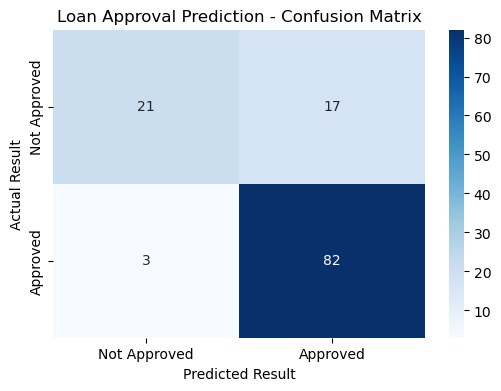

In [19]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, y_pred, labels=["N", "Y"])

plt.figure(figsize=(6, 4))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Not Approved", "Approved"],
    yticklabels=["Not Approved", "Approved"]
)

plt.xlabel("Predicted Result")
plt.ylabel("Actual Result")
plt.title("Loan Approval Prediction - Confusion Matrix")
plt.show()

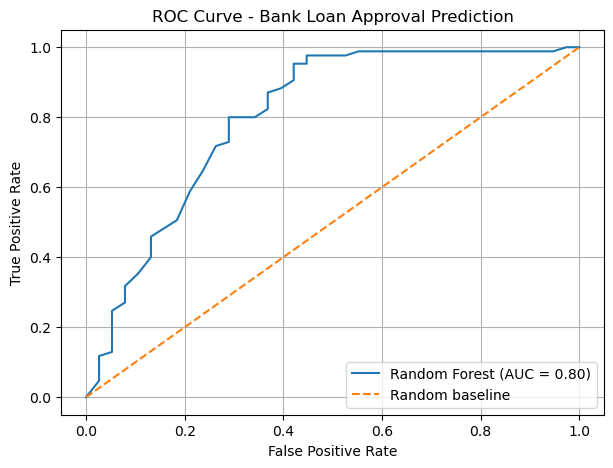

ROC-AUC Score: 0.80


In [20]:
from sklearn.metrics import roc_curve, roc_auc_score
import matplotlib.pyplot as plt

# Get probability of loan approval
y_prob = model.predict_proba(X_test_encoded)[:, 
    list(model.classes_).index("Y")
]

# Convert actual labels into binary values
y_test_binary = (y_test == "Y").astype(int)

# Calculate ROC values
fpr, tpr, thresholds = roc_curve(y_test_binary, y_prob)
auc_score = roc_auc_score(y_test_binary, y_prob)

# Plot ROC curve
plt.figure(figsize=(7, 5))
plt.plot(fpr, tpr, label=f"Random Forest (AUC = {auc_score:.2f})")
plt.plot([0, 1], [0, 1], linestyle="--", label="Random baseline")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve - Bank Loan Approval Prediction")
plt.legend()
plt.grid(True)
plt.show()

print(f"ROC-AUC Score: {auc_score:.2f}")

In [21]:
# Take one applicant record from the test dataset
sample_applicant = X_test.iloc[[0]]

# Display the applicant details
print("Sample Applicant Details:")
display(sample_applicant)

# Predict the loan outcome
prediction = model.predict(
    sample_applicant.reindex(
        columns=X_train_encoded.columns,
        fill_value=0
    ).pipe(lambda x: pd.get_dummies(x, dtype=int))
)

print("Prediction:", prediction[0])

Sample Applicant Details:


,Loan_ID,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area
150,LP001528,Male,No,0,Graduate,No,6277,0.0,118.0,360.0,0.0,Rural


Prediction: N


In [22]:
# Select one applicant from the encoded test dataset
sample_applicant = X_test_encoded.iloc[[0]]

# Predict the loan outcome
prediction = model.predict(sample_applicant)[0]

print("Predicted Loan Status:", prediction)

if prediction == "Y":
    print("Result: Loan is predicted to be APPROVED.")
else:
    print("Result: Loan is predicted to be NOT APPROVED.")

Predicted Loan Status: N
Result: Loan is predicted to be NOT APPROVED.


In [23]:
probabilities = model.predict_proba(sample_applicant)[0]

for label, probability in zip(model.classes_, probabilities):
    print(f"{label}: {probability:.2%}")

N: 90.00%
Y: 10.00%


## Conclusion

The Bank Loan Approval Prediction project uses machine learning to predict loan approval outcomes based on applicant information.

The dataset was explored and cleaned, categorical features were converted into numerical values, and a Random Forest Classifier was trained.

The model was evaluated using accuracy, precision, recall, a confusion matrix, and an ROC curve. A sample applicant was also used to demonstrate the prediction process.

This project demonstrates how machine learning can be applied to a classification problem. The model is intended for educational purposes and should not be used to make actual lending decisions without further validation, fairness assessment, and appropriate safeguards.

In [24]:
print("Model:", type(model).__name__)
print(f"Accuracy: {accuracy:.2%}")
print(f"Precision: {precision:.2%}")
print(f"Recall: {recall:.2%}")
print(f"ROC-AUC: {auc_score:.2f}")

Model: RandomForestClassifier
Accuracy: 83.74%
Precision: 82.83%
Recall: 96.47%
ROC-AUC: 0.80


In [25]:
print("Dataset shape:", df.shape)
print("Feature columns:", X.shape[1])
print("Target column:", y.name)
print("Target labels:", y.unique())
print("Missing values remaining:", df.isnull().sum().sum())
print("Model:", type(model).__name__)

Dataset shape: (614, 13)
Feature columns: 12
Target column: Loan_Status
Target labels: ['Y' 'N']
Missing values remaining: 0
Model: RandomForestClassifier


In [26]:
print("Dataset shape:", df.shape)
print("Target labels:", df["Loan_Status"].unique())
print("Missing values:", df.isnull().sum().sum())
print("Model trained:", hasattr(model, "predict"))

Dataset shape: (614, 13)
Target labels: ['Y' 'N']
Missing values: 0
Model trained: True


In [27]:

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    classification_report,
    confusion_matrix,
    roc_auc_score
)

print("Pipeline tools imported successfully!")

Pipeline tools imported successfully!


In [28]:

# Use the existing features and target
X = df.drop(columns=["Loan_Status"])
y = df["Loan_Status"]

# Identify numerical and categorical columns
numerical_features = X.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

categorical_features = X.select_dtypes(
    include=["object", "category", "bool"]
).columns.tolist()

print("Numerical features:")
print(numerical_features)

print("\nCategorical features:")
print(categorical_features)

print("\nNumber of numerical features:", len(numerical_features))
print("Number of categorical features:", len(categorical_features))

Numerical features:
['ApplicantIncome', 'CoapplicantIncome', 'LoanAmount', 'Loan_Amount_Term', 'Credit_History']

Categorical features:
['Loan_ID', 'Gender', 'Married', 'Dependents', 'Education', 'Self_Employed', 'Property_Area']

Number of numerical features: 5
Number of categorical features: 7


In [29]:

# Split the raw data before preprocessing
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training feature rows:", X_train.shape[0])
print("Testing feature rows:", X_test.shape[0])

print("\nTraining target distribution:")
print(y_train.value_counts())

print("\nTesting target distribution:")
print(y_test.value_counts())

Training feature rows: 491
Testing feature rows: 123

Training target distribution:
Loan_Status
Y    337
N    154
Name: count, dtype: int64

Testing target distribution:
Loan_Status
Y    85
N    38
Name: count, dtype: int64


In [30]:

# Preprocessing for numerical columns
numerical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median"))
])

# Preprocessing for categorical columns
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Combine both preprocessing workflows
preprocessor = ColumnTransformer(transformers=[
    ("num", numerical_transformer, numerical_features),
    ("cat", categorical_transformer, categorical_features)
])

print("Preprocessing pipeline created successfully!")

Preprocessing pipeline created successfully!


In [31]:

# Create the complete machine learning pipeline
loan_pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=100,
        random_state=42
    ))
])

print("Complete machine learning pipeline created!")

Complete machine learning pipeline created!


In [32]:

# Train preprocessing and the Random Forest model together
loan_pipeline.fit(X_train, y_train)

print("Pipeline trained successfully!")

Pipeline trained successfully!


In [33]:

# Predict using the raw test data
y_pred_pipeline = loan_pipeline.predict(X_test)

print("Predictions completed!")
print("First 10 predictions:", y_pred_pipeline[:10])
print("Actual results:", y_test.iloc[:10].values)

Predictions completed!
First 10 predictions: ['N' 'Y' 'Y' 'Y' 'Y' 'Y' 'Y' 'Y' 'Y' 'Y']
Actual results: ['N' 'Y' 'Y' 'Y' 'Y' 'N' 'Y' 'Y' 'Y' 'Y']


In [34]:

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    classification_report,
    confusion_matrix,
    roc_auc_score,
    ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt

# Calculate evaluation metrics
accuracy_pipeline = accuracy_score(y_test, y_pred_pipeline)
precision_pipeline = precision_score(
    y_test, y_pred_pipeline, pos_label="Y", zero_division=0
)
recall_pipeline = recall_score(
    y_test, y_pred_pipeline, pos_label="Y", zero_division=0
)

print(f"Accuracy:  {accuracy_pipeline:.2%}")
print(f"Precision: {precision_pipeline:.2%}")
print(f"Recall:    {recall_pipeline:.2%}")

print("\nClassification Report:")
print(classification_report(y_test, y_pred_pipeline, zero_division=0))

Accuracy:  83.74%
Precision: 82.83%
Recall:    96.47%

Classification Report:
              precision    recall  f1-score   support

           N       0.88      0.55      0.68        38
           Y       0.83      0.96      0.89        85

    accuracy                           0.84       123
   macro avg       0.85      0.76      0.78       123
weighted avg       0.84      0.84      0.83       123



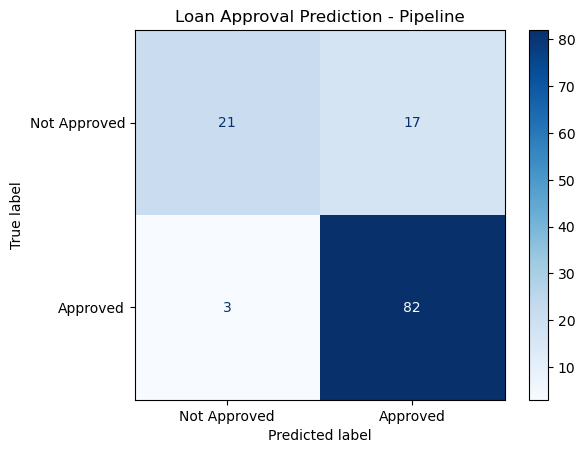

In [35]:

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred_pipeline,
    labels=["N", "Y"],
    display_labels=["Not Approved", "Approved"],
    cmap="Blues"
)

plt.title("Loan Approval Prediction - Pipeline")
plt.show()

In [36]:

# Get the probability associated with the "Y" class
class_index = list(loan_pipeline.classes_).index("Y")
y_prob_pipeline = loan_pipeline.predict_proba(X_test)[:, class_index]

# Convert actual outcomes to binary values
y_test_binary = (y_test == "Y").astype(int)

auc_pipeline = roc_auc_score(y_test_binary, y_prob_pipeline)

print(f"Pipeline ROC-AUC: {auc_pipeline:.3f}")

Pipeline ROC-AUC: 0.803


In [37]:

# Select one applicant from the test dataset
sample_applicant = X_test.iloc[[0]]

print("Sample Applicant Details:")
display(sample_applicant)

Sample Applicant Details:


,Loan_ID,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area
150,LP001528,Male,No,0,Graduate,No,6277,0.0,118.0,360.0,0.0,Rural


In [38]:

# Predict the applicant's loan status
sample_prediction = loan_pipeline.predict(sample_applicant)[0]

# Get the probability of each outcome
sample_probabilities = loan_pipeline.predict_proba(sample_applicant)[0]

print("Predicted Loan Status:", sample_prediction)

if sample_prediction == "Y":
    print("Result: Loan predicted as APPROVED")
else:
    print("Result: Loan predicted as NOT APPROVED")

print("\nEstimated class probabilities:")
for label, probability in zip(
    loan_pipeline.classes_, sample_probabilities
):
    print(f"{label}: {probability:.2%}")

Predicted Loan Status: N
Result: Loan predicted as NOT APPROVED

Estimated class probabilities:
N: 90.00%
Y: 10.00%


In [39]:

from sklearn.metrics import accuracy_score, precision_score, recall_score

# Original model predictions
original_predictions = model.predict(X_test_encoded)

# Improved Pipeline predictions
pipeline_predictions = loan_pipeline.predict(X_test)

# Compare metrics
print("MODEL PERFORMANCE COMPARISON")
print("-" * 35)

print(f"Original Model Accuracy: "
      f"{accuracy_score(y_test, original_predictions):.2%}")

print(f"Pipeline Accuracy:       "
      f"{accuracy_score(y_test, pipeline_predictions):.2%}")

print()

print(f"Original Model Precision: "
      f"{precision_score(y_test, original_predictions, pos_label='Y', zero_division=0):.2%}")

print(f"Pipeline Precision:       "
      f"{precision_score(y_test, pipeline_predictions, pos_label='Y', zero_division=0):.2%}")

print()

print(f"Original Model Recall: "
      f"{recall_score(y_test, original_predictions, pos_label='Y', zero_division=0):.2%}")

print(f"Pipeline Recall:       "
      f"{recall_score(y_test, pipeline_predictions, pos_label='Y', zero_division=0):.2%}")

MODEL PERFORMANCE COMPARISON
-----------------------------------
Original Model Accuracy: 83.74%
Pipeline Accuracy:       83.74%

Original Model Precision: 82.83%
Pipeline Precision:       82.83%

Original Model Recall: 96.47%
Pipeline Recall:       96.47%


In [40]:

# Final project verification

print("BANK LOAN APPROVAL PREDICTION")
print("=" * 35)

# 1. Check the trained Pipeline
print("Pipeline:", type(loan_pipeline).__name__)

# 2. Check predictions
final_predictions = loan_pipeline.predict(X_test)
print("Predictions generated:", len(final_predictions))

# 3. Check accuracy
final_accuracy = accuracy_score(y_test, final_predictions)
print(f"Test Accuracy: {final_accuracy:.2%}")

# 4. Check missing values in original dataset
print("Missing values in dataset:", df.isnull().sum().sum())

# 5. Check the prediction function
print("Sample prediction:", loan_pipeline.predict(X_test.iloc[[0]])[0])

print("\nFinal verification completed!")

BANK LOAN APPROVAL PREDICTION
Pipeline: Pipeline
Predictions generated: 123
Test Accuracy: 83.74%
Missing values in dataset: 0
Sample prediction: N

Final verification completed!


In [41]:

print("===== FINAL MODEL RESULTS =====")
print(f"Accuracy:  {accuracy_score(y_test, loan_pipeline.predict(X_test)):.2%}")
print(f"Precision: {precision_score(y_test, loan_pipeline.predict(X_test), pos_label='Y', zero_division=0):.2%}")
print(f"Recall:    {recall_score(y_test, loan_pipeline.predict(X_test), pos_label='Y', zero_division=0):.2%}")
print(f"ROC-AUC:   {roc_auc_score((y_test == 'Y').astype(int), loan_pipeline.predict_proba(X_test)[:, list(loan_pipeline.classes_).index('Y')]):.3f}")

===== FINAL MODEL RESULTS =====
Accuracy:  83.74%
Precision: 82.83%
Recall:    96.47%
ROC-AUC:   0.803


In [42]:

# Select a sample applicant from the test dataset
demo_applicant = X_test.iloc[[0]].copy()

# Predict the loan status
demo_prediction = loan_pipeline.predict(demo_applicant)[0]
demo_probabilities = loan_pipeline.predict_proba(demo_applicant)[0]

print("Applicant details:")
display(demo_applicant)

print("Predicted status:", demo_prediction)
print("\nEstimated probabilities:")

for label, probability in zip(loan_pipeline.classes_, demo_probabilities):
    print(f"{label}: {probability:.2%}")

Applicant details:


,Loan_ID,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area
150,LP001528,Male,No,0,Graduate,No,6277,0.0,118.0,360.0,0.0,Rural


Predicted status: N

Estimated probabilities:
N: 90.00%
Y: 10.00%
